In [32]:
import numpy as np
import matplotlib.pyplot as plt

def generate_noisy_data(model, params, x_range=(0, 10), num_points=50, noise_std=0.1, seed=None):
    """
    Generate synthetic (x, y) data based on a model function and parameters, adding Gaussian noise to y.

    Parameters:
        model (function): The function to generate y values, must take (x, params).
        params (any): Parameters to be passed to the model.
        x_range (tuple): Range of x values (min, max).
        num_points (int): Number of data points.
        noise_std (float): Standard deviation of Gaussian noise to add to y.
        seed (int or None): Seed for reproducibility.

    Returns:
        x (np.ndarray): Generated x values.
        y (np.ndarray): Corresponding noisy y values.
    """
    if seed is not None:
        np.random.seed(seed)

    x = np.linspace(*x_range, num_points)
    y_true = model(x, params)
    noise = np.random.normal(0, noise_std, size=y_true.shape)
    y_noisy = y_true + noise

    return x, y_noisy

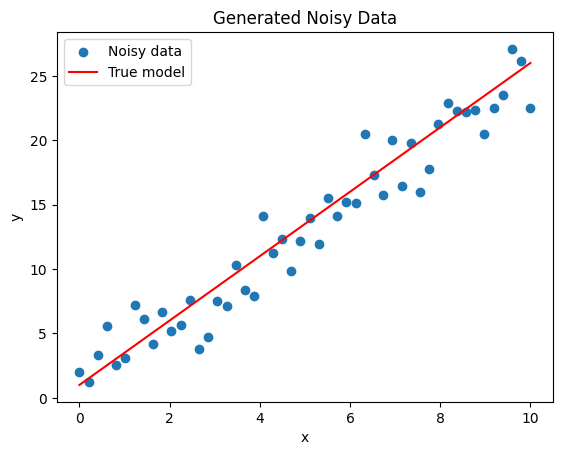

In [33]:

# Example usage
def model(x, params):
    a, b = params
    return a * x + b  # Linear model: y = ax + b

# Choose "realistic" parameters for the model
params = (2.5, 1.0)

# Generate data
x, y = generate_noisy_data(model, params, x_range=(0, 10), noise_std=2, seed=42)

# Plot
plt.scatter(x, y, label='Noisy data')
plt.plot(x, model(x, params), color='red', label='True model')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('Generated Noisy Data')
plt.show()


In [34]:
import numpy as np
import matplotlib.pyplot as plt

def generate_lens_data(f, num_points=10, p_range=(10, 50), noise_std_p=0.05, noise_std_q=0.05, seed=None):
    """
    Generate noisy measurements of p and q for a given focal length f.

    Parameters:
        f (float): The true focal length of the lens.
        num_points (int): Number of measurements to generate.
        p_range (tuple): Range of ideal p values to simulate (in cm, for example).
        noise_std_p (float): Standard deviation of noise added to p.
        noise_std_q (float): Standard deviation of noise added to q.
        seed (int or None): Seed for reproducibility.

    Returns:
        p_noisy (np.ndarray): Noisy object distances.
        q_noisy (np.ndarray): Corresponding noisy image distances.
    """
    if seed is not None:
        np.random.seed(seed)

    # Generate ideal p values within the range
    p_true = np.linspace(*p_range, num_points)

    # Calculate ideal q values using the lens formula
    q_true = 1 / (1/f - 1/p_true)

    # Add noise to p and recalculate q based on noisy p
    p_noisy = p_true + np.random.normal(0, noise_std_p, size=p_true.shape)
    q_noisy = 1 / (1/f - 1/p_noisy)

    # Optionally add noise to q directly too (e.g., measurement error)
    q_noisy += np.random.normal(0, noise_std_q, size=q_noisy.shape)

    return p_noisy, q_noisy

# Example usage
f = 3.0  # Focal length in cm
p, q = generate_lens_data(f, num_points=20, seed=1)

In [35]:
x = 1/p
y=1/q

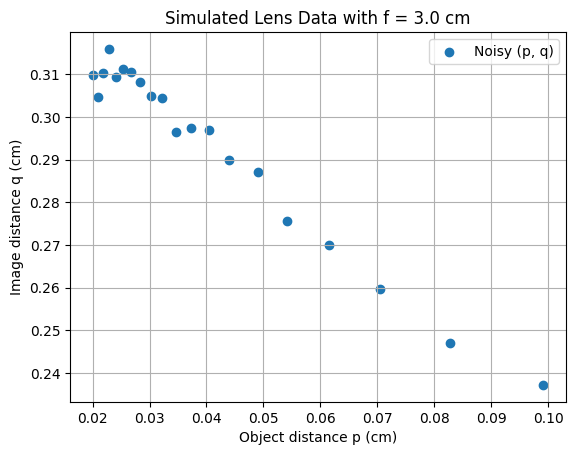

In [36]:

# Plotting
plt.scatter(x,y, label="Noisy (p, q)")
plt.xlabel("Object distance p (cm)")
plt.ylabel("Image distance q (cm)")
plt.title(f"Simulated Lens Data with f = {f} cm")
plt.grid(True)
plt.legend()
plt.show()
